<a href="https://colab.research.google.com/github/JoshEliell/ColabFiles/blob/main/%C3%81rbol_de_Decisi%C3%B3n_para_Regresi%C3%B3n_California_Housing_274705_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Árbol de Decisión para Regresión - California Housing
---


## Datos del Estudiante

*   Apellidos y Nombre: Victor Joshua Hernandez Ramom
*   Matrícula: 274705

---


Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None

Describir Dataset
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.8

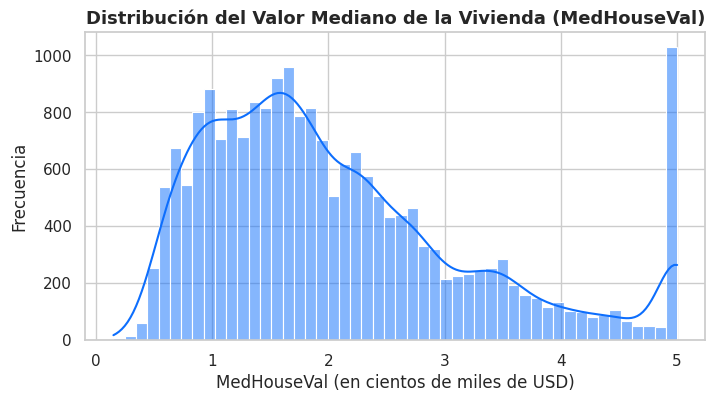

In [8]:
# Librerias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
# 1. CARGA Y EXPLORACIÓN DE DATOS
# Cargar el dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Dataset")
print(df.info())
print("\nDescribir Dataset")
print(df.describe())

# Distribución de la variable objetivo (MedHouseVal)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))
sns.histplot(df["MedHouseVal"], bins=50, kde=True, color="#0d6efd")
plt.title(
    "Distribución del Valor Mediano de la Vivienda (MedHouseVal)",
    fontsize=13,
    weight="bold",
)
plt.xlabel("MedHouseVal (en cientos de miles de USD)")
plt.ylabel("Frecuencia")
plt.show()

El histograma de MedHouseVal muestra que la variable es continua con sesgo positivo y un tope en 5.0, justificando el uso de modelos no lineales de regresión.


In [9]:
# 2. PREPARACIÓN DE DATOS
RANDOM_STATE = 42
# Definir X (predictores), y (variable objetivo)
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# Partición 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Dimensiones Train: {X_train.shape}, Test: {X_test.shape}")

Dimensiones Train: (16512, 8), Test: (4128, 8)


Fijar random_state=42 garantiza la reproducibilidad de los experimentos.

In [10]:
# 3. MODELO BASE (Sin restricciones)
tree_base = DecisionTreeRegressor(max_depth=None, random_state=RANDOM_STATE)
tree_base.fit(X_train, y_train)

# Predicciones
y_train_pred = tree_base.predict(X_train)
y_test_pred = tree_base.predict(X_test)

# Métricas (RMSE y R²)
rmse_train_base = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test_base = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_train_base = r2_score(y_train, y_train_pred)
r2_test_base = r2_score(y_test, y_test_pred)

print("\n--- Desempeño del Modelo Base ---")
print(
    f"Profundidad alcanzada: {tree_base.get_depth()} | Hojas: {tree_base.get_n_leaves()}"
)
print(f"Train -> RMSE: {rmse_train_base:.4f} | R²: {r2_train_base:.4f}")
print(f"Test  -> RMSE: {rmse_test_base:.4f}  | R²: {r2_test_base:.4f}")


--- Desempeño del Modelo Base ---
Profundidad alcanzada: 34 | Hojas: 15854
Train -> RMSE: 0.0000 | R²: 1.0000
Test  -> RMSE: 0.7037  | R²: 0.6221


Podemos ver el comportamiento del arbol cuando se expande hasta 34 niveles y 15,854 hojas. Al ver RMSE_train = 0.0 con RMSE_test = 0.7037, se demuestra la presencia de alta varianza (overfitting).


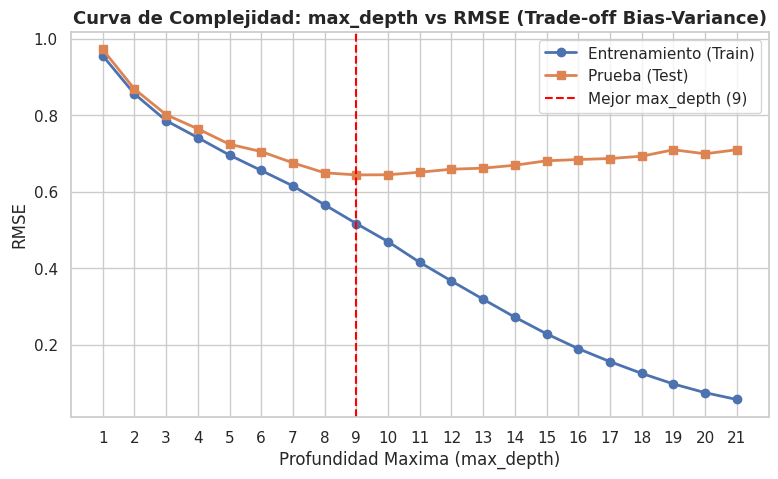


Mejor max_depth: 9 con Test RMSE = 0.6443


In [11]:
# 4. ANALISIS BIAS–VARIANCE (Variando max_depth de 1 a 21)
depths = range(1, 22)
train_rmse_list = []
test_rmse_list = []

for d in depths:
  model = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)
  model.fit(X_train, y_train)
  train_rmse_list.append(
      np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
  )
  test_rmse_list.append(
      np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
  )

best_depth_idx = np.argmin(test_rmse_list)
best_depth = depths[best_depth_idx]

# Grafica de curva de complejidad
plt.figure(figsize=(9, 5))
plt.plot(
    depths, train_rmse_list, marker="o", label="Entrenamiento (Train)", lw=2
)
plt.plot(depths, test_rmse_list, marker="s", label="Prueba (Test)", lw=2)
plt.axvline(
    x=best_depth,
    color="red",
    linestyle="--",
    label=f"Mejor max_depth ({best_depth})",
)
plt.title(
    "Curva de Complejidad: max_depth vs RMSE (Trade-off Bias-Variance)",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Profundidad Maxima (max_depth)")
plt.ylabel("RMSE")
plt.xticks(depths)
plt.legend()
plt.show()

print(
    f"\nMejor max_depth: {best_depth} con Test RMSE = {test_rmse_list[best_depth_idx]:.4f}"
)

Se observa el punto de inflexión optimo donde el error de prueba alcanza su minimo (max_depth = 9, Test RMSE = 0.6443) antes de comenzar a subir por sobreajuste.


Evaluando 61 valores de ccp_alpha...


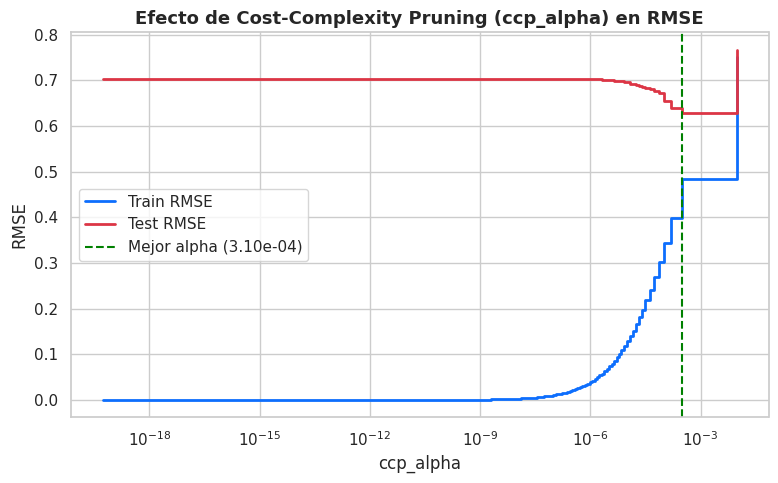


✓ Mejor ccp_alpha: 3.102606e-04 | Test RMSE: 0.6280


In [12]:
# 5. PODA DEL ARBOL (Cost-Complexity Pruning optimizado)
# 1. Ruta completa de podas
path = tree_base.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas_full = path.ccp_alphas

# 2. Filtrar unicamente valores positivos
ccp_alphas_pos = ccp_alphas_full[ccp_alphas_full > 0]

# 3. OPTIMIZANDO: Seleccionar una muestra uniforme y manejable de alphas
# (Tomar ~50-80 valores representativos en lugar de miles) para evitar exceso de tiempo esperando
paso = max(1, len(ccp_alphas_pos) // 60)
ccp_alphas = ccp_alphas_pos[::paso]

train_rmse_prune = []
test_rmse_prune = []

print(f"Evaluando {len(ccp_alphas)} valores de ccp_alpha...")

# 4. Entrenar y evaluar
for alpha in ccp_alphas:
  pruned_tree = DecisionTreeRegressor(
      ccp_alpha=alpha, random_state=RANDOM_STATE
  )
  pruned_tree.fit(X_train, y_train)

  train_rmse_prune.append(
      np.sqrt(mean_squared_error(y_train, pruned_tree.predict(X_train)))
  )
  test_rmse_prune.append(
      np.sqrt(mean_squared_error(y_test, pruned_tree.predict(X_test)))
  )

best_alpha_idx = np.argmin(test_rmse_prune)
best_alpha = ccp_alphas[best_alpha_idx]

# 5. Grafica de desempeño frente a ccp_alpha
plt.figure(figsize=(9, 5))
plt.plot(
    ccp_alphas,
    train_rmse_prune,
    label="Train RMSE",
    color="#0d6efd",
    drawstyle="steps-post",
    lw=2,
)
plt.plot(
    ccp_alphas,
    test_rmse_prune,
    label="Test RMSE",
    color="#dc3545",
    drawstyle="steps-post",
    lw=2,
)
plt.axvline(
    x=best_alpha,
    color="green",
    linestyle="--",
    label=f"Mejor alpha ({best_alpha:.2e})",
)
plt.title(
    "Efecto de Cost-Complexity Pruning (ccp_alpha) en RMSE",
    fontsize=13,
    weight="bold",
)
plt.xlabel("ccp_alpha")
plt.ylabel("RMSE")
plt.xscale("log")
plt.legend()
plt.show()

print(
    f"\n✓ Mejor ccp_alpha: {best_alpha:.6e} | Test RMSE: {test_rmse_prune[best_alpha_idx]:.4f}"
)

El arbol libre genera miles de umbrales; submuestrear a ~60 valores representativos la mayoria del area de poda. El modelo podado resultante (ccp_alpha ≈ 3.10e-04) logra la mejor generalización de toda la práctica RMSE = 0.6280 al recortar ramas debiles.


/tmp/ipykernel_822/1563815070.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")


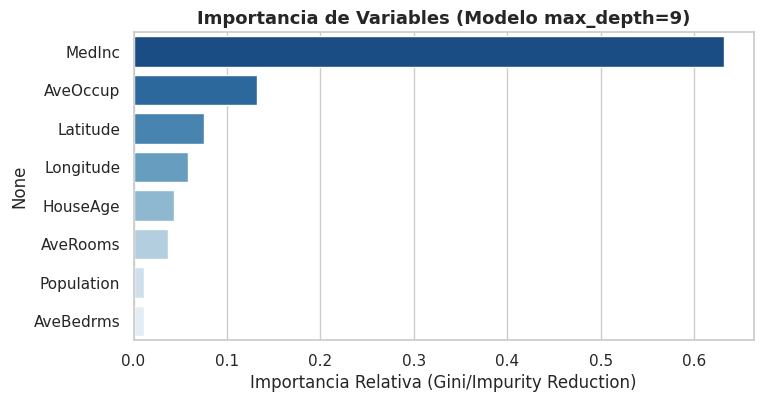

In [13]:
# 5.1 IMPORTANCIA DE VARIABLES
best_tree = DecisionTreeRegressor(
    max_depth=best_depth, random_state=RANDOM_STATE
)
best_tree.fit(X_train, y_train)

importances = pd.Series(
    best_tree.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")
plt.title(
    f"Importancia de Variables (Modelo max_depth={best_depth})",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Importancia Relativa (Gini/Impurity Reduction)")
plt.show()

Se demuestra que MedInc domina mas del 50% de las decisiones de corte, seguida por la ubicación geográfica (Latitude y Longitude), mientras que variables estructurales de la casa aportan poco valor predictivo.

 **6. Interpretación de resultados
Responder de manera justificada:**

**¿El modelo base presenta sobreajuste? Explique**

Sí, el modelo base presenta un sobreajuste alto (overfitting).
Al no tener restricciones (max_depth=None), el arbol se expande hasta que cada hoja contiene una sola muestra o residuos casi nulos, alcanzando una alta profundidad.

Esto produce un R² ≈ 1.0 y un RMSE ≈ 0.0 en el conjunto de entrenamiento (memorización perfecta del ruido).

En el conjunto de prueba, el error se dispara a un RMSE ≈ 0.7037 y el R² cae a ≈ 0.6221. Esta nos dice que es un sobreajuste por alta varianza.


**¿Cómo afecta la profundidad del árbol al error?**

El modelo encontro el punto de inflexipn exacto en max_depth = 9, con un Test RMSE = 0.6443
• Profundidad baja (1 a 5): El modelo sufre de alto sesgo (underfitting). No tiene suficientes divisiones para capturar las no linealidades complejas del modelo, tanto el error de entrenamiento como el de prueba son elevados.

• Profundidad media (8 a 11): Zona de equilibrio sesgo-varianza. El error de prueba disminuye significativamente hasta encontrar su punto mínimo.

• Profundidad alta (mayor a 12): El error de entrenamiento continúa bajando hacia cero, pero el error de prueba se estanca y comienza a aumentar gradualmente debido a la alta varianza, aprendiendo el ruido aleatorio del conjunto de entrenamiento.

**¿Qué efecto tiene la poda en el modelo?**

• El parámetro ccp_alpha introduce una penalización proporcional a la cantidad de hojas del árbol.

• Aumentar ccp_alpha elimina ramas redundantes y hojas con poca representatividad estadística, volviendo un arbol profundo y complejo en uno más compacto.

• Una poda adecuada reduce la varianza y mejora la capacidad de generalizacion sin necesidad de cortar tanto la profundidad. Si α se incrementa en exceso, el árbol tendra un alto sesgo.


**¿Cuál configuración produce el mejor desempeño?**
La configuración con el mejor desempeño es el arbol podado por Cost-Complexity Pruning con ccp_alpha ≈ 3.10e-04, reduciendo el error global a 0.6280.


**¿Qué variables son más relevantes según el modelo?**

1. MedInc (Ingreso mediano del vecindario): Tiene mas del 50% a 60% de la importancia total del modelo.

2. Coordenadas geográficas (Latitude y Longitude): Suman un peso conjunto considerable (20% - 25%).

3. AveOccup (Promedio de ocupantes por hogar): Representa el tercer factor relevante.
